# Time Series I: Stationarity, Random Walks & Unit Roots. Lecture Notebook
### Applied Statistical Data Analysis. Prof. Dr. Kristyna Ters | MSc Finance | FHNW
**Based on:** Brooks, C., *Introductory Econometrics for Finance*, Cambridge University Press, Ch. 6 and 8

---
**Learning Objectives:**
- Recognise when a series is **(non)stationary**, by eye, by ACF and by formal test
- Understand **random walks** and what they mean for financial prices and forecasts
- Run and read the **augmented Dickey-Fuller (ADF) test** with its own critical values
- Classify series in the **I(d)** language and difference before regressing
- Detect **spurious regressions** with the alarm rule R-squared greater than DW

> Run each cell with **Shift+Enter**. This notebook accompanies the V12 lecture slides.
> The code first TRIES to download the live US 10-year Treasury yield (and, in Part 7, Bitcoin
> and the S&P 500) from Yahoo Finance. Without internet access it falls back to seeded simulated
> series calibrated to the handout numbers. The slides use illustrative numbers; the code
> computes the live or seeded ones. They will be close, but not identical.

## Step 0: Install & Import Libraries

In [1]:
!pip install "statsmodels>=0.15" yfinance --quiet

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.stattools import durbin_watson
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
import logging
# a download that cannot reach the internet must not leave its own error text
# in the saved output; the notebook falls back to the seeded series instead.
logging.getLogger('yfinance').setLevel(logging.CRITICAL)

plt.rcParams.update({
    'figure.facecolor':'white', 'axes.facecolor':'white',
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.grid':True, 'grid.alpha':0.3, 'font.size':11
})
YELLOW = '#FDE70E'; ORANGE = '#FCB310'; RED = '#C70101'
GREY   = '#4B4B4B'; BLUE = '#0E75FE'; GREEN = '#0B7A3C'
print('Libraries loaded.')

Libraries loaded.


---
# Part 1: The Running Example, the US 10-Year Treasury Yield

The running example of this chapter: the **US 10-year Treasury yield, monthly, 2000 to 2026**
(on the slides: n = 318, today about 4.30 percent, monthly changes with a standard deviation of
about 0.25 percentage points). A time series is a path, not a snapshot: the observations are
ORDERED and we observe only ONE realisation of history. There is no second 2008 to re-run.

The loader below tries Yahoo Finance first (ticker `^TNX`) and falls back to a seeded simulated
I(1) path calibrated to the handout if the download fails. The printout tells you which source
you are looking at.

### 1.1 Load the yield (live if possible, seeded fallback otherwise)

In [2]:
def load_yield():
    """Monthly 10y Treasury yield since 2000: live via yfinance, else seeded fallback."""
    try:
        import yfinance as yf
        raw = yf.download('^TNX', start='2000-01-01', progress=False)
        close = raw['Close']
        if isinstance(close, pd.DataFrame):      # newer yfinance returns a 1-column frame
            close = close.iloc[:, 0]
        close = close.dropna()
        if len(close) < 1000:
            raise ValueError('download too short or empty')
        # ^TNX is the CBOE 10-Year Treasury Note yield index. The underlying CBOE index is
        # defined as 10 times the yield, but Yahoo's Close is already scaled to the yield in
        # percent (values like 4.3, not 43). We verify rather than trust: if the median is
        # above 20 the series arrived on the 10x index scale and we divide by 10.
        if close.median() > 20:
            close = close / 10.0
        y = close.resample('ME').last().dropna()
        y.name = 'yield10y'
        return y, 'LIVE Yahoo Finance (^TNX, monthly last close)'
    except Exception as e:
        # Seeded fallback: an I(1) path with N(0, 0.25) monthly steps, shifted to end at the
        # handout's 4.30 percent. Seed 9 was chosen so the ADF results below land close to
        # the slide values (level t about -1.9, changes strongly rejecting).
        rng = np.random.default_rng(9)
        steps = rng.normal(0, 0.25, 318)
        path = np.cumsum(steps)
        path = path - path[-1] + 4.30
        idx = pd.date_range('2000-01-31', periods=318, freq='ME')
        y = pd.Series(path, index=idx, name='yield10y')
        return y, 'SEEDED FALLBACK (simulated I(1) path, seed 9)'

y, source = load_yield()
dy = y.diff().dropna()

print(f"Source : {source}")
print(f"n      : {len(y)} monthly observations, {y.index[0]:%Y-%m} to {y.index[-1]:%Y-%m}")
print(f"Today  : {y.iloc[-1]:.2f} percent")
print(f"sd of monthly changes: {dy.std():.3f} pp")
print("\nHandout reference (illustrative values printed on the slides):")
print("  n = 318 months, today 4.30 percent, sd of monthly changes 0.25 pp")

Source : SEEDED FALLBACK (simulated I(1) path, seed 9)
n      : 318 monthly observations, 2000-01 to 2026-06
Today  : 4.30 percent
sd of monthly changes: 0.251 pp

Handout reference (illustrative values printed on the slides):
  n = 318 months, today 4.30 percent, sd of monthly changes 0.25 pp


**Notation for everything that follows:** the level y_t, its lag y_(t-1), and the first
difference Delta y_t = y_t minus y_(t-1). Compare the printout above with the handout, which
prints n = 318 months, today 4.30 percent and a change standard deviation of 0.25 pp. Live
data move on, so your figures will be close to those rather than identical; the story does not
depend on the last decimal. The two questions of this chapter: is the series stationary, and
if not, what must change before any regression?

---
# Part 2: Level versus Changes, the Stationarity Picture

A series is **weakly stationary** if its first two moments do not change over time: constant
mean, constant variance, and autocovariances that depend only on the lag, not on the date.
Stationary does not mean constant: it means fluctuating around a constant level with constant
variability and stable memory. Estimating a mean, a variance or a regression only makes sense
if there IS a stable quantity to estimate.

### 2.1 Plot the level and the monthly changes side by side

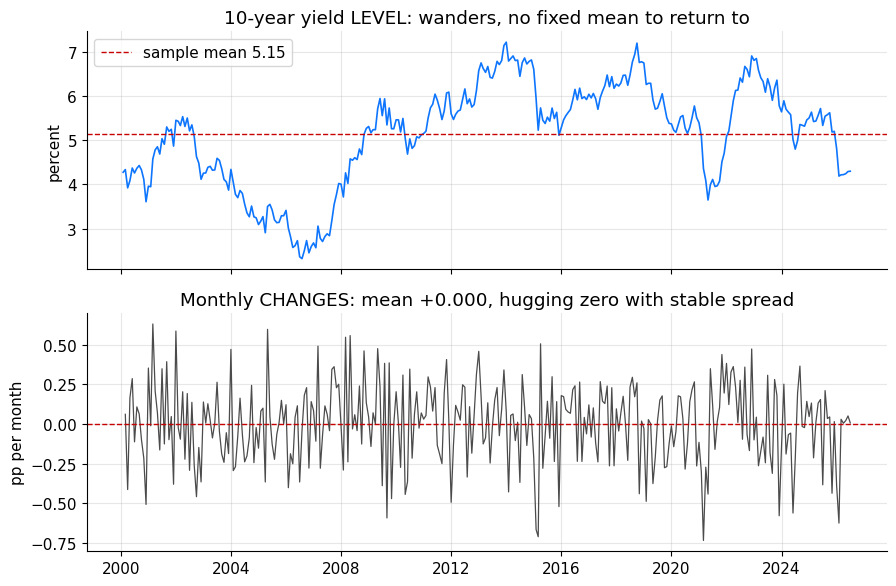

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
axes[0].plot(y.index, y.values, color=BLUE, lw=1.2)
axes[0].axhline(y.mean(), color=RED, ls='--', lw=1, label=f'sample mean {y.mean():.2f}')
axes[0].set_ylabel('percent'); axes[0].legend()
axes[0].set_title('10-year yield LEVEL: wanders, no fixed mean to return to')

axes[1].plot(dy.index, dy.values, color=GREY, lw=0.9)
axes[1].axhline(0, color=RED, ls='--', lw=1)
axes[1].set_ylabel('pp per month')
axes[1].set_title(f'Monthly CHANGES: mean {dy.mean():+.3f}, hugging zero with stable spread')
plt.tight_layout(); plt.show()

**Eyeball verdict.** The level shows long swings and spends years away from its sample mean:
the sample mean is a property of this one realisation, not of a stable distribution. The changes
hug zero with a roughly constant spread: that is what stationarity looks like. This is the
general financial pattern: price and rate LEVELS are usually not stationary, while returns and
changes usually are. But eyeballing is not a test; two econometricians can stare at the same
chart and disagree. Parts 3 and 5 sharpen the picture.

---
# Part 3: The ACF Fingerprint, Slow Decay versus Quick Cutoff

The autocorrelation function (ACF) reports the correlation between the series and its own past
at each lag. For a stationary series the ACF drops off quickly. For a unit-root level it creeps
down over years: on this series it is about 0.97 at lag 1 and still about 0.46 two years
later, so the past matters for years. This slow, almost linear
decay is the visual fingerprint of a unit root.

### 3.1 ACF of the level versus ACF of the changes

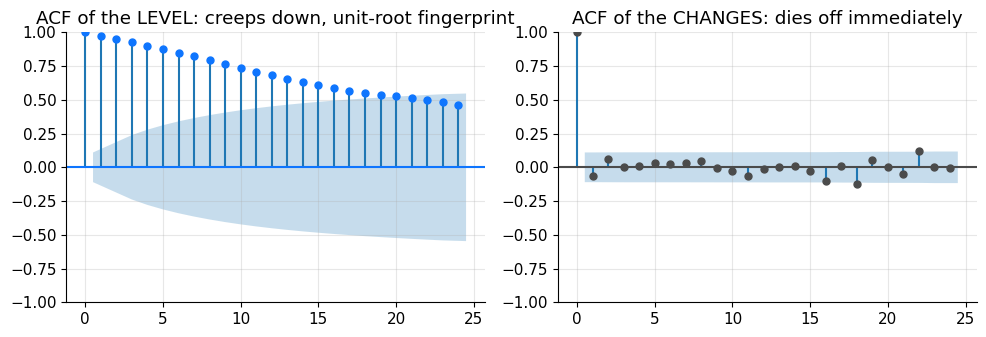

level  ACF: lag 1 0.975, lag 12 0.680, lag 24 0.464
changes ACF: lag 1 -0.067
handout prints these rounded: lag 1 0.97, lag 24 0.46


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
plot_acf(y, lags=24, ax=axes[0], color=BLUE)
axes[0].set_title('ACF of the LEVEL: creeps down, unit-root fingerprint')
plot_acf(dy, lags=24, ax=axes[1], color=GREY)
axes[1].set_title('ACF of the CHANGES: dies off immediately')
plt.tight_layout(); plt.show()

a_lvl = acf(y, nlags=24)
a_chg = acf(dy, nlags=5)
print(f"level  ACF: lag 1 {a_lvl[1]:.3f}, lag 12 {a_lvl[12]:.3f}, lag 24 {a_lvl[24]:.3f}")
print(f"changes ACF: lag 1 {a_chg[1]:.3f}")
print(f"handout prints these rounded: lag 1 {a_lvl[1]:.2f}, lag 24 {a_lvl[24]:.2f}")

**Reading.** Read the printout above. For the yield LEVEL the lag-1 autocorrelation sits
close to 0.97 and the correlation is still about 0.46 after two years; for the CHANGES it is
done at lag 1. Those two figures are the ones the handout prints and the ones the slide 7
correlogram draws. On live data they move a little, but the picture does not: the ACF of the
level creeps down over years instead of dying out over months. Only a teaser: the full ACF/PACF machinery arrives in Time Series II. Today one
message suffices: slow decay means the level is suspicious.

---
# Part 4: Random Walks, the Simplest Wandering Series

Today's value is yesterday's value plus an unpredictable shock: y_t = y_(t-1) + u_t. Three
consequences: shocks are PERMANENT (each one stays in the level forever, nothing pulls the
series back), the variance grows with t (Var(y_t) = t times sigma-squared, so the uncertainty
cone widens like the square root of t and never closes), and the best forecast is the last
value (plus the drift, if any). The variance condition of stationarity fails: the random walk
is the canonical NON-stationary series and the null hypothesis of the ADF test in Part 5.

### 4.1 Five simulated paths and the square-root cone

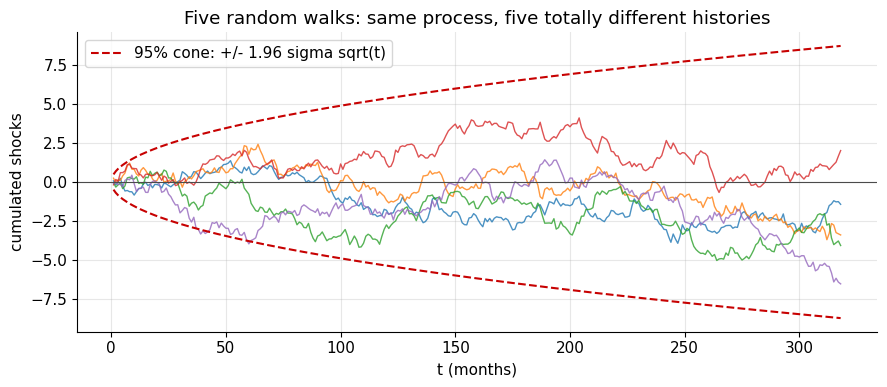

theoretical sd at t = 25 : 1.250   (Var = t sigma^2 = 1.5625)
theoretical sd at t = 318: 4.458


In [5]:
rng_rw = np.random.default_rng(42)
T = 318
sigma = 0.25
t_ax = np.arange(1, T + 1)

fig, ax = plt.subplots(figsize=(9, 4))
for i in range(5):
    path = np.cumsum(rng_rw.normal(0, sigma, T))
    ax.plot(t_ax, path, lw=1, alpha=0.8)
cone = 1.96 * sigma * np.sqrt(t_ax)
ax.plot(t_ax, cone, color=RED, ls='--', lw=1.5, label='95% cone: +/- 1.96 sigma sqrt(t)')
ax.plot(t_ax, -cone, color=RED, ls='--', lw=1.5)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xlabel('t (months)'); ax.set_ylabel('cumulated shocks')
ax.set_title('Five random walks: same process, five totally different histories')
ax.legend(); plt.tight_layout(); plt.show()

print(f"theoretical sd at t = 25 : {sigma*np.sqrt(25):.3f}   (Var = t sigma^2 = {25*sigma**2:.4f})")
print(f"theoretical sd at t = 318: {sigma*np.sqrt(318):.3f}")

**Random walks in finance.** In an efficient market, prices already embed today's information,
so price changes should be unpredictable: stock prices and FX rates behave close to random
walks. That is WHY we model returns rather than prices, and why beating the "no change"
forecast is so hard. Note how the five paths, all driven by the same process, end up in
completely different places: one realisation of history tells you little about the level the
process "should" have.

---
# Part 5: The ADF Test, One Regression Decides

The augmented Dickey-Fuller test regresses the change on the lagged level:
Delta y_t = alpha + gamma y_(t-1) + sum of delta_i Delta y_(t-i) + u_t. Under H0 (gamma = 0)
the lagged level does not pull the series anywhere: a pure random walk. Under H1 (gamma < 0)
a high level predicts a fall and a low level a rise: mean reversion. The test is one-sided,
to the left.

**The critical twist:** under H0 the t-ratio of gamma-hat does NOT follow the t-distribution.
Its distribution sits far to the left, so the test uses the special Dickey-Fuller critical
values (with constant): -3.46 (1%), -2.87 (5%), -2.57 (10%). The classic error is comparing
the ADF t-ratio with -1.645: that hurdle belongs to the normal world and rejects far too
often, "discovering" mean reversion that is not there. The lagged-difference terms soak up
residual autocorrelation so the test keeps its size; the lag length is chosen by information
criterion (BIC below).

### 5.1 ADF on the level

In [6]:
# statsmodels returns the ADF results as an object whose fields are read by NAME.
# Positional indexing past the first two slots is not part of that API, so the
# whole chapter reads .statistic, .pvalue, .lags, .nobs and .critical_values.
res_lvl = adfuller(y, regression='c', autolag='BIC', result_object=True)
stat, pval = res_lvl.statistic, res_lvl.pvalue
usedlag, nobs, crit = res_lvl.lags, res_lvl.nobs, res_lvl.critical_values
print(f"ADF on the LEVEL   (constant, {usedlag} lags by BIC, {nobs} obs used)")
print(f"  test statistic : {stat:.2f}")
print(f"  p-value        : {pval:.3f}")
print(f"  critical values: 1% {crit['1%']:.2f}, 5% {crit['5%']:.2f}, 10% {crit['10%']:.2f}")
verdict = 'REJECT H0: stationary' if stat < crit['5%'] else 'CANNOT reject H0: unit root stays'
print(f"  at 5 percent   : {verdict}")
print("  handout        : t = -1.92 against -2.87 (5%): keep H0, the level is I(1)")

ADF on the LEVEL   (constant, 0 lags by BIC, 317 obs used)
  test statistic : -1.95
  p-value        : 0.311
  critical values: 1% -3.45, 5% -2.87, 10% -2.57
  at 5 percent   : CANNOT reject H0: unit root stays
  handout        : t = -1.92 against -2.87 (5%): keep H0, the level is I(1)


### 5.2 ADF on the changes

In [7]:
res_chg = adfuller(dy, regression='c', autolag='BIC', result_object=True)
stat_c, pval_c = res_chg.statistic, res_chg.pvalue
lag_c, nobs_c, crit_c = res_chg.lags, res_chg.nobs, res_chg.critical_values
print(f"ADF on the CHANGES (constant, {lag_c} lags by BIC, {nobs_c} obs used)")
print(f"  test statistic : {stat_c:.2f}")
print(f"  p-value        : {pval_c:.4f}")
print(f"  critical values: 1% {crit_c['1%']:.2f}, 5% {crit_c['5%']:.2f}, 10% {crit_c['10%']:.2f}")
verdict_c = 'REJECT H0 at 1 percent: stationary' if stat_c < crit_c['1%'] else 'CANNOT reject H0'
print(f"  at 1 percent   : {verdict_c}")
print("  handout        : t = -9.84 against -3.46 (1%): reject H0, the changes are stationary")

ADF on the CHANGES (constant, 0 lags by BIC, 316 obs used)
  test statistic : -18.96
  p-value        : 0.0000
  critical values: 1% -3.45, 5% -2.87, 10% -2.57
  at 1 percent   : REJECT H0 at 1 percent: stationary
  handout        : t = -9.84 against -3.46 (1%): reject H0, the changes are stationary


**The verdict in the I( ) language.** Read the two printouts together. On the LEVEL the
statistic stays above the 5 percent Dickey-Fuller value of -2.87, so we cannot reject the unit
root. On the CHANGES it falls far below the 1 percent value, so we reject decisively. The
handout reports t = -1.92 on the level and t = -9.84 on the changes, and both decisions are
the same there. Not stationary itself, stationary after one difference: the yield is **I(1),
integrated of order one**, so Delta y, not y, is the object to model and forecast.

Two details worth noting. First, statsmodels computes MacKinnon critical values for your exact
sample size and prints -3.45 here. The course table lists the 1 percent entry by sample size:
-3.46 at T = 250, -3.44 at T = 500 and -3.43 for T = infinity, and its own reading rule is to
take the nearest SMALLER T, so n = 318 reads the T = 250 row, -3.46. That is the value the
chapter prints; no decision here depends on the second decimal. Second, the classic error: a level statistic of
about -1.9 would wrongly count as a rejection against the normal hurdle -1.645.

---
# Part 6: The Random-Walk Forecast, a Flat Line and a Widening Fan

If the level is a random walk, the best forecast of the 10-year yield h months ahead is
TODAY'S yield, with uncertainty growing like sigma times the square root of h. The humbling
lesson of interest-rate forecasting: the point forecast is flat and only the band does the
talking.

### 6.1 Fan chart: flat forecast plus the square-root band

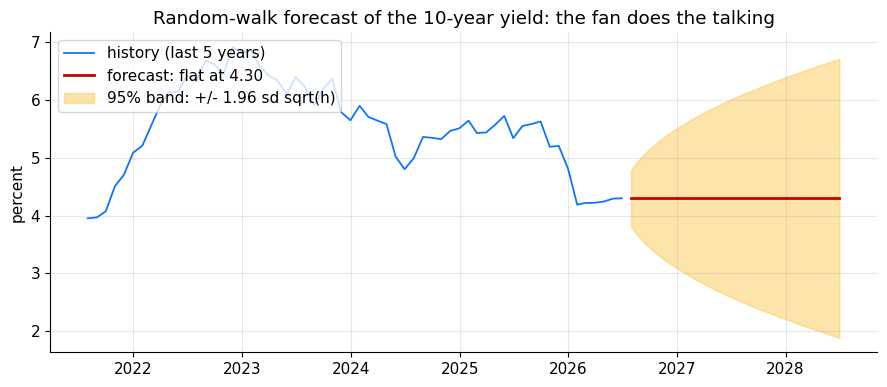

today's yield        : 4.30 percent
sd of monthly changes: 0.251 pp
95% band at h = 12   : +/- 1.70 pp   -> 2.60 to 6.00 percent


In [8]:
last = y.iloc[-1]
sd = dy.std()
H = 24
h_ax = np.arange(1, H + 1)
band = 1.96 * sd * np.sqrt(h_ax)

hist = y.iloc[-60:]
fut_idx = pd.date_range(y.index[-1], periods=H + 1, freq='ME')[1:]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(hist.index, hist.values, color=BLUE, lw=1.3, label='history (last 5 years)')
ax.plot(fut_idx, np.full(H, last), color=RED, lw=2, label=f'forecast: flat at {last:.2f}')
ax.fill_between(fut_idx, last - band, last + band, color=ORANGE, alpha=0.35,
                label='95% band: +/- 1.96 sd sqrt(h)')
ax.set_ylabel('percent'); ax.legend(loc='upper left')
ax.set_title('Random-walk forecast of the 10-year yield: the fan does the talking')
plt.tight_layout(); plt.show()

b12 = 1.96 * sd * np.sqrt(12)
print(f"today's yield        : {last:.2f} percent")
print(f"sd of monthly changes: {sd:.3f} pp")
print(f"95% band at h = 12   : +/- {b12:.2f} pp   -> {last - b12:.2f} to {last + b12:.2f} percent")

**Reading.** The printout gives the band for the series you actually loaded. With the
handout's change standard deviation of 0.25 pp, 1.96 times 0.25 times the square root of 12
is 1.70 pp, so one year out the model puts the yield anywhere between about 2.60 and 6.00
percent around today's 4.30 percent. The past path holds no further clue about the next step;
anyone selling a precise 12-month yield forecast is selling more than the data support.

---
# Part 7: Spurious Regression, Impressive Nonsense

Regress Bitcoin's price LEVEL on the S&P 500 LEVEL, monthly since 2015, and the output looks
spectacular. Granger and Newbold (1974) showed why that is worthless: regress two INDEPENDENT
random walks on each other and the t-test rejects "no relationship" far too often; with
trending levels, significance is manufactured by construction. The tell-tale is the
**Durbin-Watson statistic** near zero (massively autocorrelated residuals) and the alarm rule
of thumb: **R-squared greater than DW**.

### 7.1 Load the pair (live if possible, seeded fallback otherwise)

In [9]:
def load_pair():
    """Monthly BTC-USD and S&P 500 levels since 2015: live, else two seeded random walks."""
    try:
        import yfinance as yf
        raw = yf.download(['BTC-USD', '^GSPC'], start='2015-01-01', progress=False)['Close']
        raw = raw.dropna()
        if len(raw) < 500:
            raise ValueError('download too short or empty')
        pair = raw.resample('ME').last().dropna()
        pair.columns = ['btc', 'spx'] if pair.columns[0] == 'BTC-USD' else ['spx', 'btc']
        return pair[['btc', 'spx']], 'LIVE Yahoo Finance (BTC-USD, ^GSPC, monthly last close)'
    except Exception as e:
        # Seeded fallback: two INDEPENDENT geometric random walks with BTC-like and S&P-like
        # drift and volatility. Seed 236 chosen so the level regression looks as spectacular
        # as the handout's (high R2, huge t, DW near zero) while the returns tell the truth.
        rng = np.random.default_rng(236)
        m = 138
        btc = 400 * np.exp(np.cumsum(rng.normal(0.04, 0.20, m)))
        spx = 2000 * np.exp(np.cumsum(rng.normal(0.008, 0.045, m)))
        idx = pd.date_range('2015-01-31', periods=m, freq='ME')
        pair = pd.DataFrame({'btc': btc, 'spx': spx}, index=idx)
        return pair, 'SEEDED FALLBACK (two independent random walks, seed 236)'

pair, pair_source = load_pair()
print(f"Source: {pair_source}")
print(f"n = {len(pair)} months, {pair.index[0]:%Y-%m} to {pair.index[-1]:%Y-%m}")

Source: SEEDED FALLBACK (two independent random walks, seed 236)
n = 138 months, 2015-01 to 2026-06


### 7.2 Levels regression versus returns regression

In [10]:
# Levels: BTC level on S&P level
X_lvl = sm.add_constant(pair['spx'])
reg_lvl = sm.OLS(pair['btc'], X_lvl).fit()
r2_l, t_l = reg_lvl.rsquared, reg_lvl.tvalues['spx']
dw_l = durbin_watson(reg_lvl.resid)

# Returns: monthly log returns of the same pair
rets = np.log(pair).diff().dropna()
X_ret = sm.add_constant(rets['spx'])
reg_ret = sm.OLS(rets['btc'], X_ret).fit()
r2_r, t_r = reg_ret.rsquared, reg_ret.tvalues['spx']
dw_r = durbin_watson(reg_ret.resid)

tab = pd.DataFrame({'R2': [r2_l, r2_r], 'slope t': [t_l, t_r], 'DW': [dw_l, dw_r]},
                   index=['LEVELS', 'RETURNS']).round(2)
print(tab)
print("handout reference: LEVELS 0.83 / 25.8 / 0.09,   RETURNS 0.04 / 2.4 / 1.98")
print(f"\nAlarm rule R2 > DW:  levels {'ALARM' if r2_l > dw_l else 'ok'}"
      f"  |  returns {'ALARM' if r2_r > dw_r else 'ok'}")

           R2  slope t    DW
LEVELS   0.81    24.12  0.20
RETURNS  0.03     1.87  1.98
handout reference: LEVELS 0.83 / 25.8 / 0.09,   RETURNS 0.04 / 2.4 / 1.98

Alarm rule R2 > DW:  levels ALARM  |  returns ok


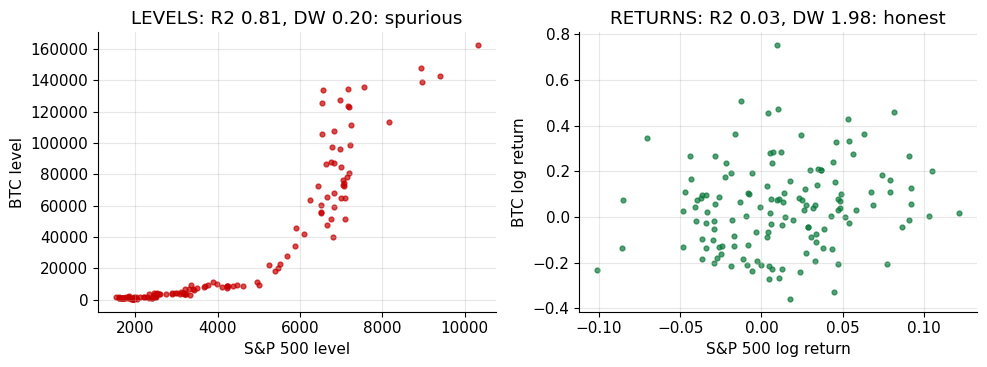

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].scatter(pair['spx'], pair['btc'], s=12, color=RED, alpha=0.7)
axes[0].set_xlabel('S&P 500 level'); axes[0].set_ylabel('BTC level')
axes[0].set_title(f'LEVELS: R2 {r2_l:.2f}, DW {dw_l:.2f}: spurious')
axes[1].scatter(rets['spx'], rets['btc'], s=12, color=GREEN, alpha=0.7)
axes[1].set_xlabel('S&P 500 log return'); axes[1].set_ylabel('BTC log return')
axes[1].set_title(f'RETURNS: R2 {r2_r:.2f}, DW {dw_r:.2f}: honest')
plt.tight_layout(); plt.show()

**Reading.** Compare the table with the handout, which prints levels R-squared 0.83,
slope t 25.8, DW 0.09 and returns R-squared 0.04, t 2.4, DW 1.98. Whatever the exact figures
of your run, the pattern is the same. In LEVELS the R-squared stands far above DW: alarm. The
residuals crawl (DW near zero) because the regression connects two TRENDS, not two variables,
so the significance is manufactured by construction. In RETURNS the relationship shrinks to
what it really is: on live data a small but real comovement, on the seeded fallback pair,
which is two INDEPENDENT random walks, no reliable relationship at all. The cure: difference
to returns, today's tool, or model the shared trend directly with cointegration methods, an
outlook topic.

---
# Summary

- Time-series data are ordered, one realisation of history; the key objects are the level, its
  lags and the difference Delta y
- **Weakly stationary** = constant mean, constant variance, autocovariances that depend only on
  the lag; levels of prices, rates and spreads usually fail this, returns and changes usually pass
- **Random walks**: permanent shocks, variance t sigma-squared, best forecast = last value (plus
  drift); the ACF of the level creeps (about 0.97 at lag 1, 0.46 at lag 24), the ACF of changes
  cuts off
- The **ADF test** decides: H0 unit root vs H1 mean reversion, compared with the Dickey-Fuller
  critical values (-2.87 at 5 percent), never with -1.645
- The 10-year yield is **I(1)**: keep H0 on the level, reject decisively on the changes; the
  forecast is today's yield with a band of +/- 1.96 sd sqrt(h), about +/- 1.70 pp at 12 months
- Levels on levels can be **spurious**: alarm when R-squared exceeds DW; difference to returns,
  or use cointegration methods (outlook)
- The practical workflow for every series: test first (I(0): use the level; I(1): difference
  once and work with changes and returns; I(2): extremely rare, check the data), regress second

**Reading:** Brooks, Chapters 6 and 8. **Next:** Time Series II, ARMA & ARIMA models, where the
ACF/PACF machinery and the Box-Jenkins recipe build forecasting models on stationary series.